In [2]:
import cv2
import numpy as np
from IPython.display import display
from PIL import Image
import os


In [3]:
# 
# ############ the grid detection
#

In [4]:
def shortest_des_point_line(rho, theta, p_x, p_y):
    
    # if result < 0 point is left or top
    # if result > 0 point is right or down
    # dif is abs(xcos(ta) + ysin(ta)) - abs(rho)
    return float( abs(p_y * np.cos(theta) + p_x * np.sin(theta)) - abs(rho))

def point_to_line_given_x(rho, theta, x):
    return float((rho - x * np.sin(theta)) / np.cos(theta))

def point_to_line_given_y(rho, theta, y):
    return float((rho - y * np.cos(theta)) / np.sin(theta))

def lineDistance_dif(rho1, rho2):
    return abs(rho1) - abs(rho2)   # (1) - (2) if > 0 (1) is right hand side of (2)      < 0 otherwiss


In [5]:
# is point is left or top
def isPointIsLeftOfTheline(startPoint, line):
    return shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1]) < 0

def findNearestLineWithIndexRet(startPoint, lines):
    lpds= [(
        line[0], #rho, 
        line[1], #theta, 
        abs(shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1])),
        idx)
        for idx, line in enumerate(lines)]
    sortedLpds = sorted(lpds, key = lambda x: x[2])
    return (sortedLpds[0][0:2], sortedLpds[0][3])


# start point (x, y)   lines = [(rho, theta)]
def findNearestLine(startPoint, lines):
    # line point distance (rho, theta, distance)
    line, idx = findNearestLineWithIndexRet(startPoint, lines)
    return line

In [6]:
# start point (x, y)    
# lines = [ (rho, theta)]    
# we assume line is either horizontal or vertical
# we assume line is either side  left-right or top-down
# amt amount of line to be recruite (centerline is not included)
# direction is either true is left false is right (reference form polar)

#
IMAGE_WIDTH = 920
IMAGE_HEIGHT = 920



def filterLeftByRelDistance(lineWithDistance, isLeft: bool):
                # < 0 mean its rho is less than center
    return (lineWithDistance[2] <= 0) == isLeft


def select_lineByDistance(minBlockLength: float, maxBlockLength: float, 
                          startPoint, lines, 
                          amt, isLeft: bool, isVertical: bool,
                          minStopBlockLength: float, maxStopBlockLength: float,
                          startStopBlockAtLine: int): # centerline not include
    
    centerLine = findNearestLine(startPoint, lines)

    # line with distance
    #(rho, theta, difFrameMastsesr)
    # minus because we want line to point

    lds = []

    for rho, theta in lines:
        if isVertical:
            ld = (rho, theta, point_to_line_given_x(rho, theta, IMAGE_HEIGHT//2)- float(IMAGE_WIDTH//2))
            lds.append(ld)
        else:
            ld = (rho, theta, point_to_line_given_y(rho, theta, IMAGE_WIDTH//2)- float(IMAGE_HEIGHT//2))
            lds.append(ld)
        

    # filter to the wanted direction
    lds = list(filter(lambda x: filterLeftByRelDistance(x, isLeft),lds))
    # sorted by length
    lds = sorted(lds, key = lambda x: abs(x[2]))

    resultAmt = 0

    curline = (centerLine[0], centerLine[1], 0)
    result = []
    boundLine = None    


    for line in lds:
        print("------finding block")
        print("------------dis of line ", line[2])
        print("------------dis of curline", curline[2])
        lineDifSize = abs(line[2] - curline[2])

        print(lineDifSize)
        if (resultAmt >= startStopBlockAtLine):
            print("checking bound ", startStopBlockAtLine)
            if((lineDifSize >= minStopBlockLength) and (lineDifSize < maxStopBlockLength)):
                print("boundDectect")
                boundLine = line
                break
            
        print("checking ", minBlockLength, " ",maxBlockLength)
        print(type(lineDifSize), type(minBlockLength), type(maxBlockLength))
        if (lineDifSize >= minBlockLength) and (lineDifSize  < maxBlockLength):
            result.append(line)
            curline = line
            resultAmt = resultAmt + 1
            print("newLineAss")

        # in case bound line is not detected we must break it

        if resultAmt == amt:
            break
        print("--")
        
    
    if (boundLine != None):
            boundLine = boundLine[0:2]

    return [(rho, theta) for rho, theta, _ in result], centerLine, boundLine




In [7]:
def filterVerHolByTheta(line, isVertical):
    theta = line[1]
    verAng0 = 45/180*np.pi
    verAng1 = 125/180*np.pi

    if (theta < 0 or theta >= np.pi):
        print(theta)
        print("invalid angle")

    return isVertical == ((theta >= verAng1)or (theta <= verAng0))


def select_lineByDirection(lines, isVertical):
    return list(filter(lambda x: filterVerHolByTheta(x, isVertical),lines))

In [8]:
BLOCK_PER_CHESS_SIDE = 4
def joinTwoSideLines(leftLines, leftCenterLine, leftBoundLine, rightLines, rightBoundLine):
    
    if ((leftBoundLine != None) and (rightBoundLine != None)):
        result = leftLines[::-1] + [leftCenterLine]
        remain = (BLOCK_PER_CHESS_SIDE * 2) - len(leftLines)
        return result + rightLines[:remain]
    else:
        return leftLines[::-4][:4] + [leftCenterLine] + rightLines[:4]



In [9]:
def selectLine(lines, minBoxWidth, maxBoxWidth, startingPoint, minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine): # centerline not include
    

    #print("starting point is ")
    #print(startingPoint)

    # detectVertical

    linePerSide = 5

    allVerticalLine = select_lineByDirection(lines, True)

    print("veritcalline ",len(allVerticalLine))
    print("all vertical line is ")
    print(allVerticalLine)
    ###############
    # Vertical line
    ###############
    
    leftVerticals , centerLine0, leftBoundLine  = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allVerticalLine, \
                              linePerSide, True, True, \
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine
                                )
    
    print("vericalRight")
    #print("")
    rightVerticals, centerLine1, rightBoundLine = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allVerticalLine, \
                              linePerSide, False,True,  \
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine)
    #print("--------------------")
    
    VerticalResult = joinTwoSideLines(leftVerticals, centerLine0, leftBoundLine, rightVerticals, rightBoundLine)#leftVerticals[::-1] + [centerLine0]# + rightVerticals

    ##############
    # Horizon line
    ##############
    allHorizontalLine = select_lineByDirection(lines, False)

    print("horizonline ",len(allHorizontalLine))
    print("all vertical line is ")
    print(allVerticalLine)
    leftHorizon , centerLineH0, topBoundLine = \
        select_lineByDistance(minBoxWidth, maxBoxWidth, \
                              startingPoint, allHorizontalLine, \
                              linePerSide, True, False,
                              minStopBoxWidth, maxStopBoxWidth, \
                              startStopBlockAtLine)
    rightHorizon, centerLineH1, bottomBoundLine = \
      select_lineByDistance(minBoxWidth, maxBoxWidth, \
                            startingPoint, allHorizontalLine, \
                            linePerSide, False, False,
                            minStopBoxWidth, maxStopBoxWidth, \
                            startStopBlockAtLine)
    
    
    HorizonResult = joinTwoSideLines(leftHorizon, centerLineH0, topBoundLine, rightHorizon, bottomBoundLine)#leftVerticals[::-1] + [centerLine0]# + rightVerticals

    #return (leftVerticals + rightVerticals, leftHorizon + rightHorizon), (leftBoundLine, rightBoundLine, topBoundLine, bottomBoundLine)
    return (VerticalResult, HorizonResult), (leftBoundLine, rightBoundLine, topBoundLine, bottomBoundLine)

In [10]:
def embededLine(image, lines, color):
    for rho, theta in lines:
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 3000 * (-b))
        y1 = int(y0 + 3000 * (a))
        x2 = int(x0 - 3000 * (-b))
        y2 = int(y0 - 3000 * (a))
        cv2.line(image, (x1, y1), (x2, y2), color, 2)

def embededPoint(image, point):
    
    color = (0,0,255)
    radius = 40
    thickness = -1
    cv2.circle(image, point[::-1], radius, color, thickness)

def embededParameter(image, name, value):     # embed also support  gray scale image
    
    text = f"{name}: {str(value)}"
    position = (60, 30)  # Adjust position for each line
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 3
    color = (0, 255, 0)  # Green text
    thickness = 2

    cv2.putText(image, text, position, font, font_scale, color, thickness)
    return image



In [11]:
def gridDetect(image, minBoxValueSize, maxBoxValueSize, startingPoint, poolAmtHough, minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply edge detection
    edges = cv2.Canny(gray, 50, 150)
    lines = cv2.HoughLines(edges, 1, np.pi / 360, poolAmtHough)
    myLine = [tuple(line[0]) for line in lines ]
    (VerticalResult, HorizontalResult), bounds = selectLine(\
        myLine, minBoxValueSize, maxBoxValueSize, startingPoint,\
        minStopBoxWidth, maxStopBoxWidth, startStopBlockAtLine)
    return (VerticalResult, HorizontalResult), bounds

In [12]:
def nextConsecutiveCell(resultLine, resultLineIdx, point, maxLineIdx): # amount of line 

    if (resultLineIdx == 0):
        return 1
    if (resultLineIdx == maxLineIdx):
        return maxLineIdx - 1

    ### the point is in the left of the line 
    if isPointIsLeftOfTheline(point, resultLine):
        return resultLineIdx - 1
    else:
        return resultLineIdx + 1

def cellDetect(HorizontalResults, VerticalResults, point):


    lineH, idxH = findNearestLineWithIndexRet(point, HorizontalResults)
    lineV, idxV = findNearestLineWithIndexRet(point, VerticalResults)

    idxHc = nextConsecutiveCell(lineH, idxH, point, len(HorizontalResults)-1)
    idxVc = nextConsecutiveCell(lineV, idxV, point, len(VerticalResults)-1)

    #### return (x, y)
    return min(idxH, idxHc), min(idxV, idxVc)

In [13]:
def isLeftSmallerThanRight(lines, isVertical):

    leftPair  = lines[0:2]
    rightPair = lines[-2:]

    if (isVertical):
        xMiddle = IMAGE_HEIGHT // 2

        yl1 = point_to_line_given_x(leftPair[0][0], leftPair[0][1],  xMiddle)
        yl2 = point_to_line_given_x(leftPair[1][0], leftPair[1][1],  xMiddle)

        yr1 = point_to_line_given_x(rightPair[0][0], rightPair[0][1], xMiddle)
        yr2 = point_to_line_given_x(rightPair[1][0], rightPair[1][1], xMiddle)

        diffl = abs(yl1 - yl2)
        diffr = abs(yr1 - yr2)
        return diffl < diffr
    
    else:
        
        yMiddle = IMAGE_WIDTH // 2

        xl1 = point_to_line_given_y(leftPair[0][0], leftPair[0][1],  yMiddle)
        xl2 = point_to_line_given_y(leftPair[1][0], leftPair[1][1],  yMiddle)

        xr1 = point_to_line_given_y(rightPair[0][0], rightPair[0][1], yMiddle)
        xr2 = point_to_line_given_y(rightPair[1][0], rightPair[1][1], yMiddle)

        diffl = abs(xl1 - xl2)
        diffr = abs(xr1 - xr2)
        return diffl < diffr

In [14]:
maskGrid         = None
HSV_HUMAN_LOWER  = np.array([ 0,  48,  80], dtype = "uint8")
HSV_HUMAN_UPPER  = np.array([20, 255, 255], dtype = "uint8")

In [15]:
def s2_markGrid(rho, theta, xOrdi, yOrdi, isLeft):
    #print((yOrdi * np.cos(theta)).dtype)
    absDisToLineGrid = \
        abs(yOrdi * np.cos(theta) + xOrdi * np.sin(theta)) - abs(rho)
    
    return isLeft == (absDisToLineGrid < 0)

def s2_initGridMask(image, topLine, rightLine, downLine, leftLine):
    global maskGrid

    x, y = np.ogrid[:image.shape[0],:image.shape[1]]

    # top and down
    topClean   = s2_markGrid(topLine  [0], topLine  [1], x, y, False)
    downClean  = s2_markGrid(downLine [0], downLine [1], x, y, True )
    # right and left
    rightClean = s2_markGrid(rightLine[0], rightLine[1], x, y, True )
    leftClean  = s2_markGrid(leftLine [0], leftLine [1], x, y, False)

    maskGrid = topClean & downClean & rightClean & leftClean

def s2_initMaskHuman(image, boundMask):

    # skinMask = cv2.inRange(imageHSV, HSV_HUMAN_LOWER, HSV_HUMAN_UPPER).astype(bool)

    # print("skinMask", skinMask.shape, skinMask.dtype)
    # print("boundMask", boundMask.shape, boundMask.dtype)

    # summaryMask = skinMask & boundMask
    # display(Image.fromarray(summaryMask))

    # Kovac et al

    B_Frame = image[:, :,0]
    G_Frame = image[:, :,1]
    R_Frame = image[:, :,2]

    bgr_max = np.maximum.reduce([B_Frame, G_Frame, R_Frame])
    bgr_min = np.minimum.reduce([B_Frame, G_Frame, R_Frame])

    r1 = np.logical_and.reduce([R_Frame > 95, G_Frame > 40, B_Frame > 20,
                         (bgr_max - bgr_min) > 15, abs(R_Frame- G_Frame) > 15,
                         R_Frame > G_Frame, R_Frame > B_Frame])
    
    # r2 = np.logical_and.reduce([R_Frame > 220, G_Frame > 210, B_Frame > 170,
    #                             abs(R_Frame- G_Frame) <= 15, 
    #                             R_Frame > B_Frame, G_Frame > B_Frame])

    summaryMask = r1
    summaryMask = np.logical_and(summaryMask, boundMask)

    return summaryMask

    

In [16]:



def s2_handDetect(srcVideoPath, desVideoPath):
    print(srcVideoPath)

    cap  =  cv2.VideoCapture(srcVideoPath)

    #### init video
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    out = cv2.VideoWriter(desVideoPath, fourcc, fps, frame_size)

    VerticalResult = None
    HorizontalResult = None

    ret, frame = cap.read()
    (VerticalResult, HorizontalResult), bounds\
        = gridDetect(frame, 88, 178, (frame.shape[0]//2, frame.shape[1]//2), 200, 35, 75, 3)

    while cap.isOpened():
        #print("xxxx")
        ret, frame = cap.read()
        if not ret:
            break
        #print("finread")
        
        
        s2_initGridMask(frame, HorizontalResult[0], VerticalResult[-1], HorizontalResult[-1], VerticalResult[0])

        maskedPic = s2_initMaskHuman(frame, maskGrid)
        #print("masking")
        frame[maskedPic] = [0,0,255]
        #print("fin")
        count = np.sum(maskedPic)

        cv2.putText(frame, f"handCorlor Count{str(count)}", 
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 
                    1, (0, 255, 0), 2)
        out.write(frame)
        
    cap.release()
    out.release()
    print(f"Video capture and writing complete.{desVideoPath}")


video_directory = 'vdo'
output_directory = 'out_withHandMask2'


#s2_handDetect(os.path.join(video_directory,"2_move_student.mp4"), os.path.join(output_directory, "2_move_student.mp4"))
#s2_handDetect( "vdo/2_move_student.mp4", "out_withHandMask2/2_move_student.mp4")   

for video_file in os.listdir(video_directory):
    s2_handDetect(os.path.join(video_directory,video_file), os.path.join(output_directory, f"outV_{video_file}"))


    

vdo/6_Move_student.mp4
veritcalline  30
all vertical line is 
[(1.0, 0.0), (437.0, 0.008726646), (-636.0, 3.1241393), (-739.0, 3.1154127), (-934.0, 3.0892327), (-968.0, 3.0717795), (-833.0, 3.0979593), (541.0, 0.0), (340.0, 0.02617994), (-977.0, 3.080506), (134.0, 0.05235988), (-925.0, 3.080506), (136.0, 0.05235988), (89.0, 0.061086524), (81.0, 0.05235988), (144.0, 0.061086524), (-936.0, 3.0892327), (242.0, 0.04363323), (233.0, 0.034906585), (92.0, 0.061086524), (330.0, 0.017453292), (-988.0, 3.080506), (235.0, 0.034906585), (-730.0, 3.106686), (84.0, 0.05235988), (-533.0, 3.132866), (-975.0, 3.080506), (-732.0, 3.106686), (151.0, 0.06981317), (-994.0, 3.0892327)]
------finding block
------------dis of line  -26.997714350489957
------------dis of curline 0
26.997714350489957
checking  88   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -131.92897783628587
------------dis of curline 0
131.92897783628587
checking  88   178
<class 'float'> 

KeyboardInterrupt: 

(1920, 1080, 3)
veritcalline  34
all vertical line is 
[(18.0, 0.0), (973.0, 0.0), (1079.0, 0.0), (1028.0, 0.0), (756.0, 0.008726646), (348.0, 0.017453292), (971.0, 0.0), (119.0, 0.02617994), (860.0, 0.0), (1026.0, 0.0), (163.0, 0.02617994), (448.0, 0.017453292), (656.0, 0.017453292), (647.0, 0.008726646), (251.0, 0.017453292), (551.0, 0.017453292), (868.0, 0.008726646), (440.0, 0.008726646), (1033.0, 0.008726646), (543.0, 0.008726646), (156.0, 0.017453292), (-1017.0, 3.132866), (536.0, 0.0), (111.0, 0.017453292), (642.0, 0.0), (-962.0, 3.132866), (981.0, 0.008726646), (749.0, 0.0), (-964.0, 3.132866), (561.0, 0.02617994), (170.0, 0.034906585), (767.0, 0.017453292), (-1019.0, 3.132866), (154.0, 0.017453292)]
------finding block
------------dis of line  -19.961093185430116
------------dis of curline 0
19.961093185430116
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -23.99760008403382
------------dis of curline 0
23.9976000

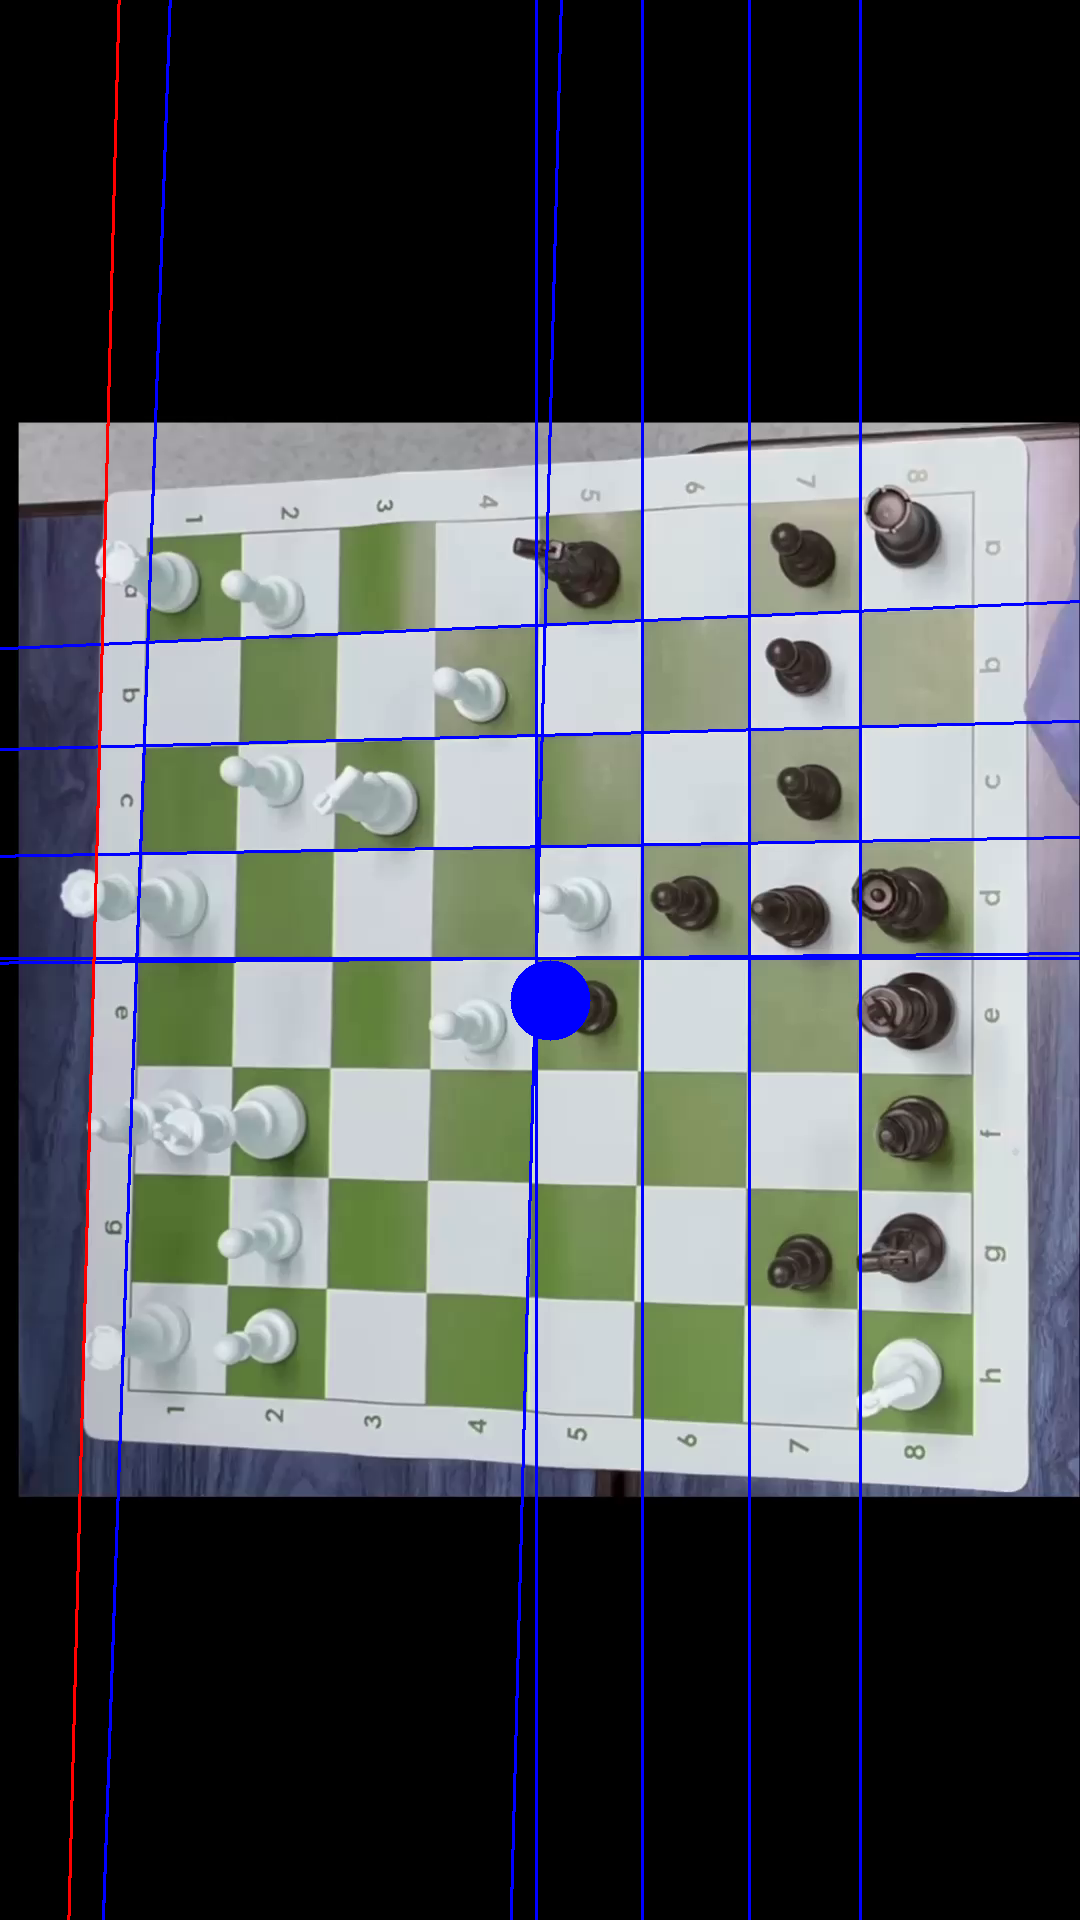

(0, 2)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(1920, 1080, 3)
veritcalline  31
all vertical line is 
[(1.0, 0.0), (542.0, 0.0), (438.0, 0.008726646), (-937.0, 3.0892327), (-740.0, 3.1154127), (135.0, 0.05235988), (-979.0, 3.080506), (-844.0, 3.106686), (83.0, 0.05235988), (340.0, 0.02617994), (233.0, 0.034906585), (137.0, 0.05235988), (-646.0, 3.132866), (-934.0, 3.0892327), (144.0, 0.061086524), (331.0, 0.017453292), (-968.0, 3.0717795), (-636.0, 3.1241393), (242.0, 0.04363323), (128.0, 0.04363323), (93.0, 0.061086524), (-927.0, 3.080506), (-925.0, 3.080506), (-946.0, 3.0979593), (89.0, 0.061086524), (-835.0, 3.0979593), (-638.0, 3.1241393), (-842.0, 3.106686), (141.0, 0.061086524), (-981.0, 3.080506), (-971.0, 3.0717795)]
------finding block
------------dis of line  -25.997676261671245
------------dis of curline 0
25.997676261671245
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -131.92897783628587
-----

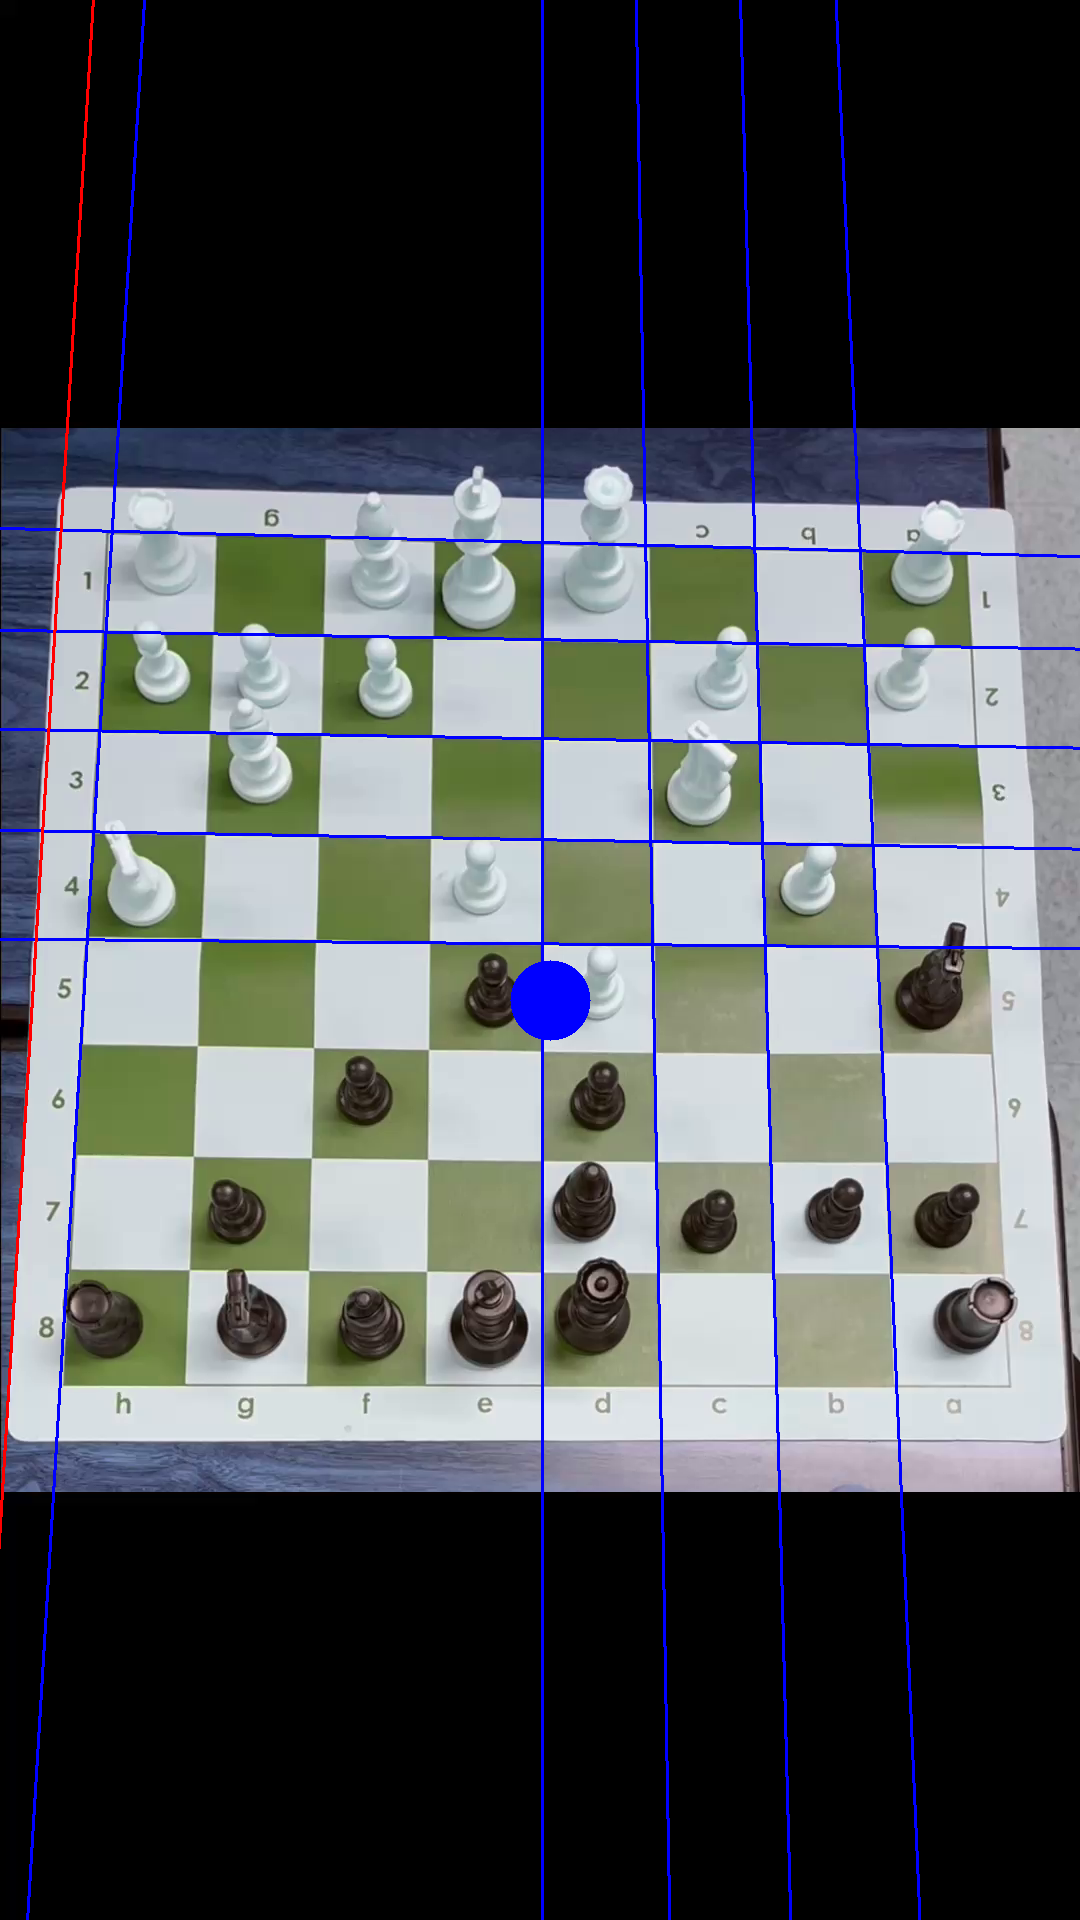

(0, 1)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(1920, 1080, 3)
veritcalline  30
all vertical line is 
[(1.0, 0.0), (437.0, 0.008726646), (-636.0, 3.1241393), (-739.0, 3.1154127), (-934.0, 3.0892327), (-968.0, 3.0717795), (-833.0, 3.0979593), (541.0, 0.0), (340.0, 0.02617994), (-977.0, 3.080506), (134.0, 0.05235988), (-925.0, 3.080506), (136.0, 0.05235988), (89.0, 0.061086524), (81.0, 0.05235988), (144.0, 0.061086524), (-936.0, 3.0892327), (242.0, 0.04363323), (233.0, 0.034906585), (92.0, 0.061086524), (330.0, 0.017453292), (-988.0, 3.080506), (235.0, 0.034906585), (-730.0, 3.106686), (84.0, 0.05235988), (-533.0, 3.132866), (-975.0, 3.080506), (-732.0, 3.106686), (151.0, 0.06981317), (-994.0, 3.0892327)]
------finding block
------------dis of line  -26.997714350489957
------------dis of curline 0
26.997714350489957
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -131.92897783628587
------------dis of curline 

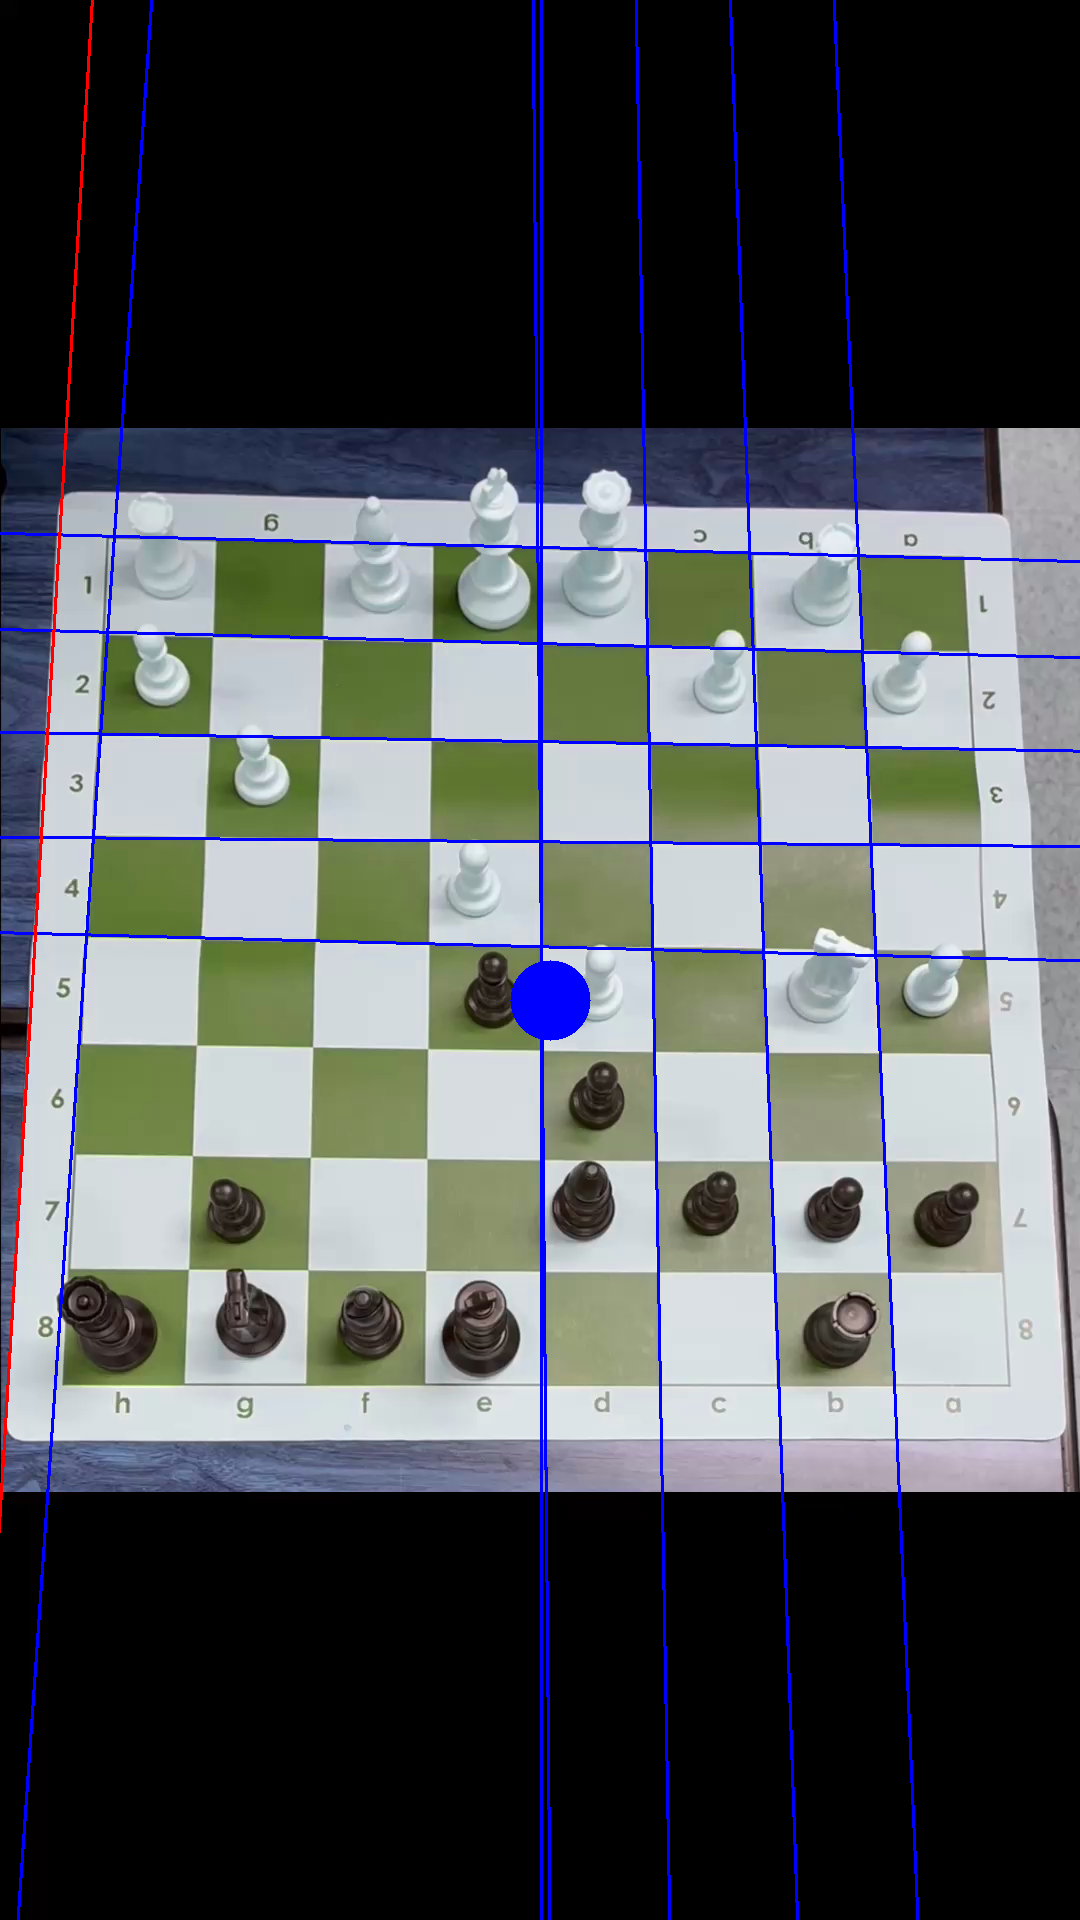

(0, 2)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(1920, 1080, 3)
veritcalline  30
all vertical line is 
[(1.0, 0.0), (-648.0, 3.132866), (-845.0, 3.106686), (93.0, 0.061086524), (245.0, 0.04363323), (343.0, 0.02617994), (544.0, 0.0), (448.0, 0.017453292), (146.0, 0.061086524), (138.0, 0.05235988), (-991.0, 3.0892327), (-751.0, 3.1241393), (-982.0, 3.080506), (-946.0, 3.0979593), (-938.0, 3.0892327), (-744.0, 3.1154127), (-948.0, 3.0979593), (-988.0, 3.0892327), (-741.0, 3.1154127), (235.0, 0.034906585), (552.0, 0.008726646), (-995.0, 3.0892327), (-973.0, 3.0717795), (135.0, 0.05235988), (133.0, 0.04363323), (127.0, 0.04363323), (154.0, 0.06981317), (439.0, 0.008726646), (-926.0, 3.080506), (350.0, 0.034906585)]
------finding block
------------dis of line  -19.961093185430116
------------dis of curline 0
19.961093185430116
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -24.997638172852533
------------dis of cu

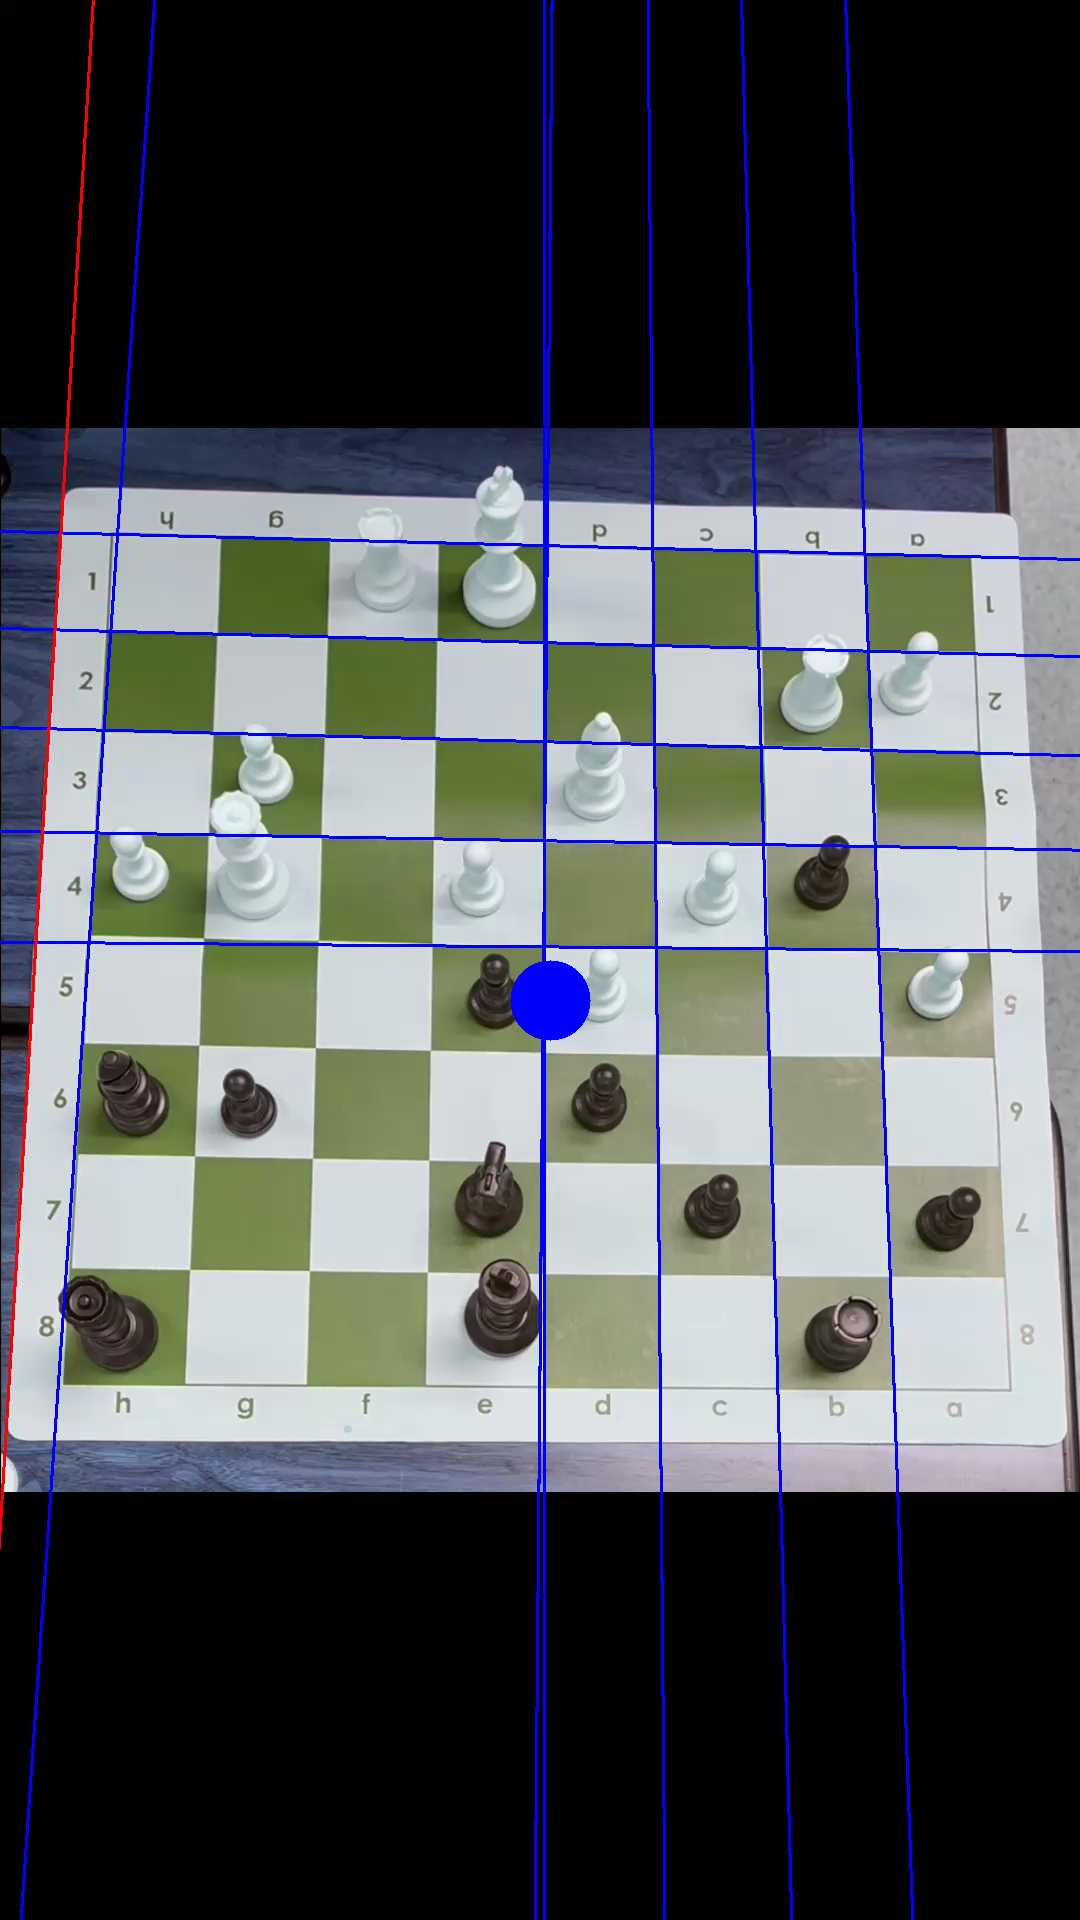

(0, 2)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(1920, 1080, 3)
veritcalline  30
all vertical line is 
[(1061.0, 0.0), (0.0, 0.0), (764.0, 0.017453292), (106.0, 0.0), (51.0, 0.0), (1010.0, 0.02617994), (108.0, 0.0), (340.0, 0.008726646), (219.0, 0.0), (53.0, 0.0), (966.0, 0.02617994), (456.0, 0.017453292), (448.0, 0.008726646), (862.0, 0.017453292), (664.0, 0.017453292), (227.0, 0.008726646), (552.0, 0.008726646), (562.0, 0.017453292), (1001.0, 0.017453292), (63.0, 0.008726646), (115.0, 0.008726646), (656.0, 0.008726646), (543.0, 0.0), (-98.0, 3.132866), (330.0, 0.0), (437.0, 0.0), (-100.0, 3.132866), (957.0, 0.017453292), (-45.0, 3.132866), (568.0, 0.02617994)]
------finding block
------------dis of line  -11.959874680924997
------------dis of curline 0
11.959874680924997
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -15.997295373484121
------------dis of curline 0
15.997295373484121
checking  75   178
<cl

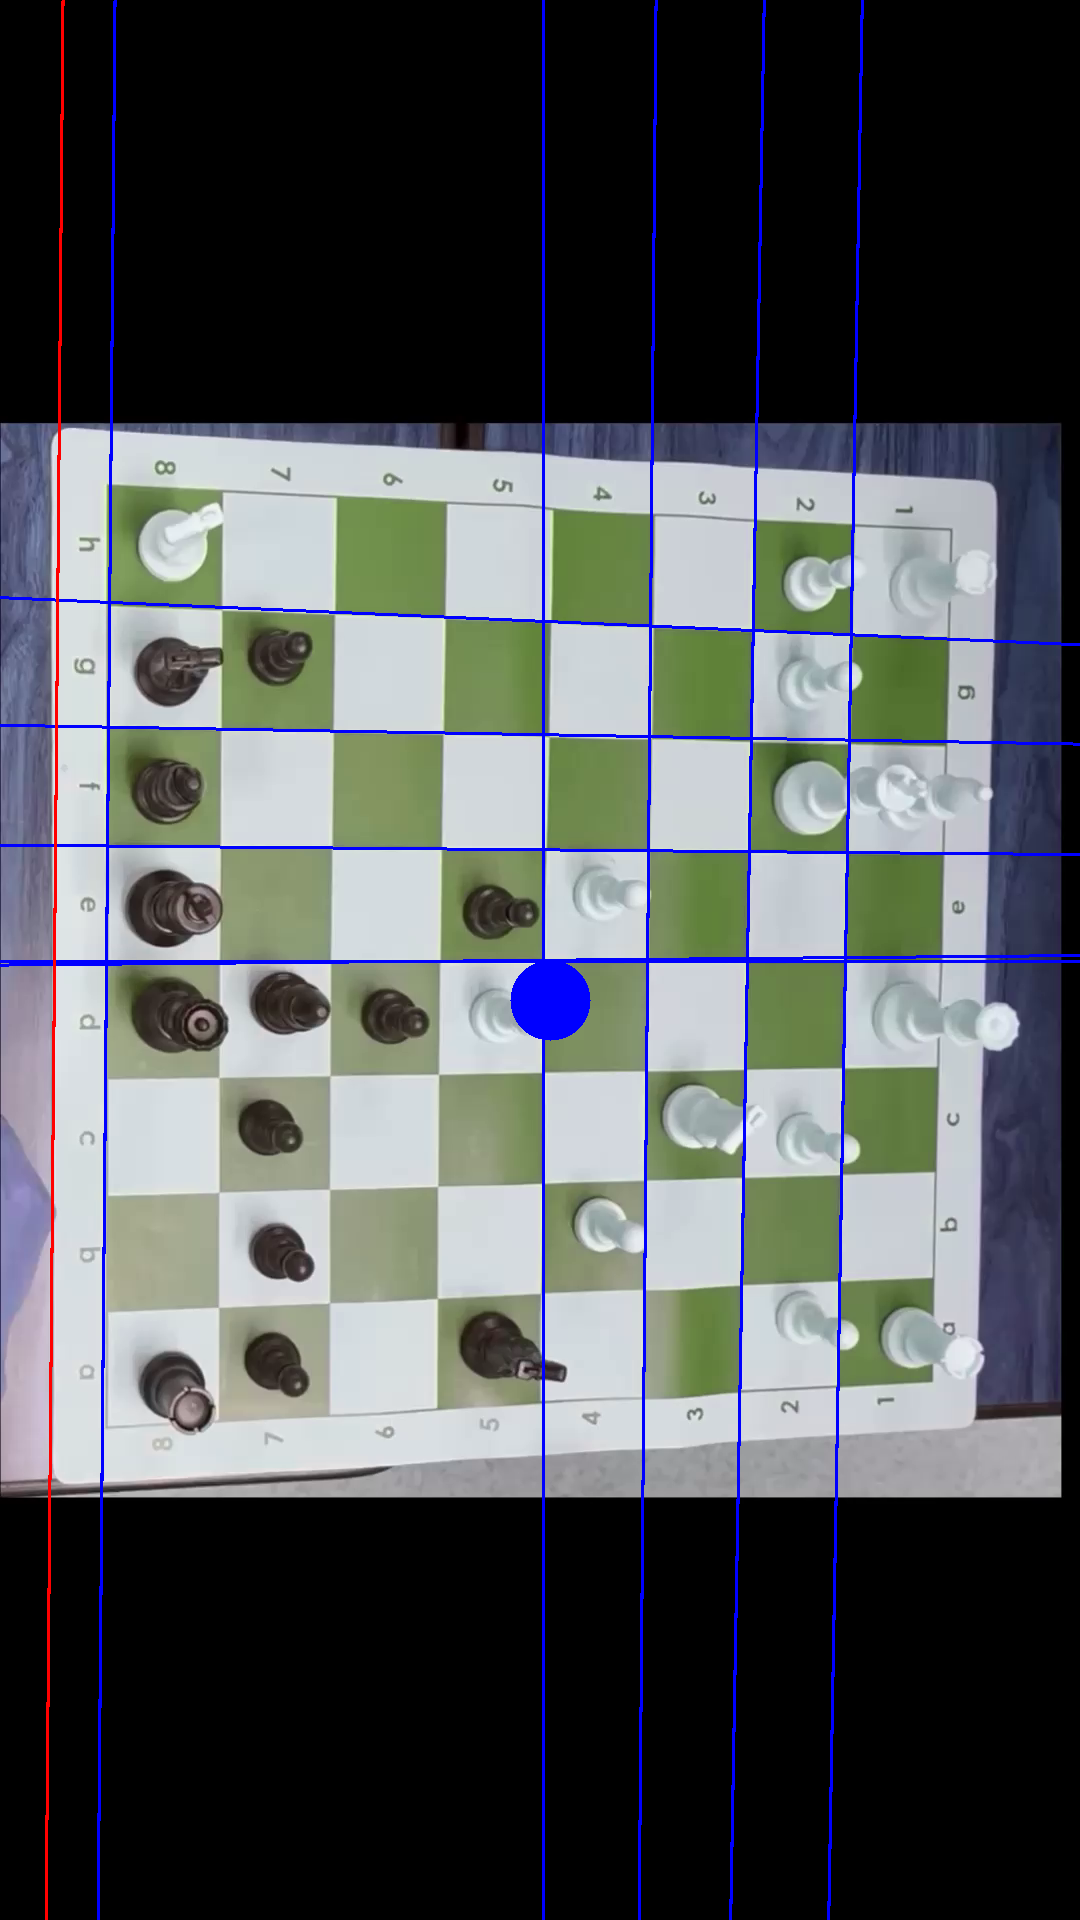

(3, 1)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(1920, 1080, 3)
veritcalline  33
all vertical line is 
[(1078.0, 0.0), (-288.0, 3.1154127), (537.0, 0.0), (658.0, 0.008726646), (-40.0, 3.0892327), (1043.0, 0.05235988), (19.0, 3.080506), (1095.0, 0.05235988), (912.0, 0.034906585), (789.0, 0.02617994), (-167.0, 3.106686), (1041.0, 0.05235988), (-409.0, 3.1241393), (-43.0, 3.0892327), (781.0, 0.017453292), (-416.0, 3.132866), (1050.0, 0.061086524), (1033.0, 0.04363323), (-35.0, 3.080506), (920.0, 0.04363323), (-407.0, 3.1241393), (1101.0, 0.061086524), (-32.0, 3.080506), (25.0, 3.0717795), (-529.0, 3.132866), (-160.0, 3.0979593), (1053.0, 0.061086524), (-48.0, 3.0979593), (28.0, 3.0717795), (21.0, 3.080506), (30.0, 3.0717795), (1106.0, 0.061086524), (1089.0, 0.04363323)]
------finding block
------------dis of line  -39.96974918885422
------------dis of curline 0
39.96974918885422
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
----------

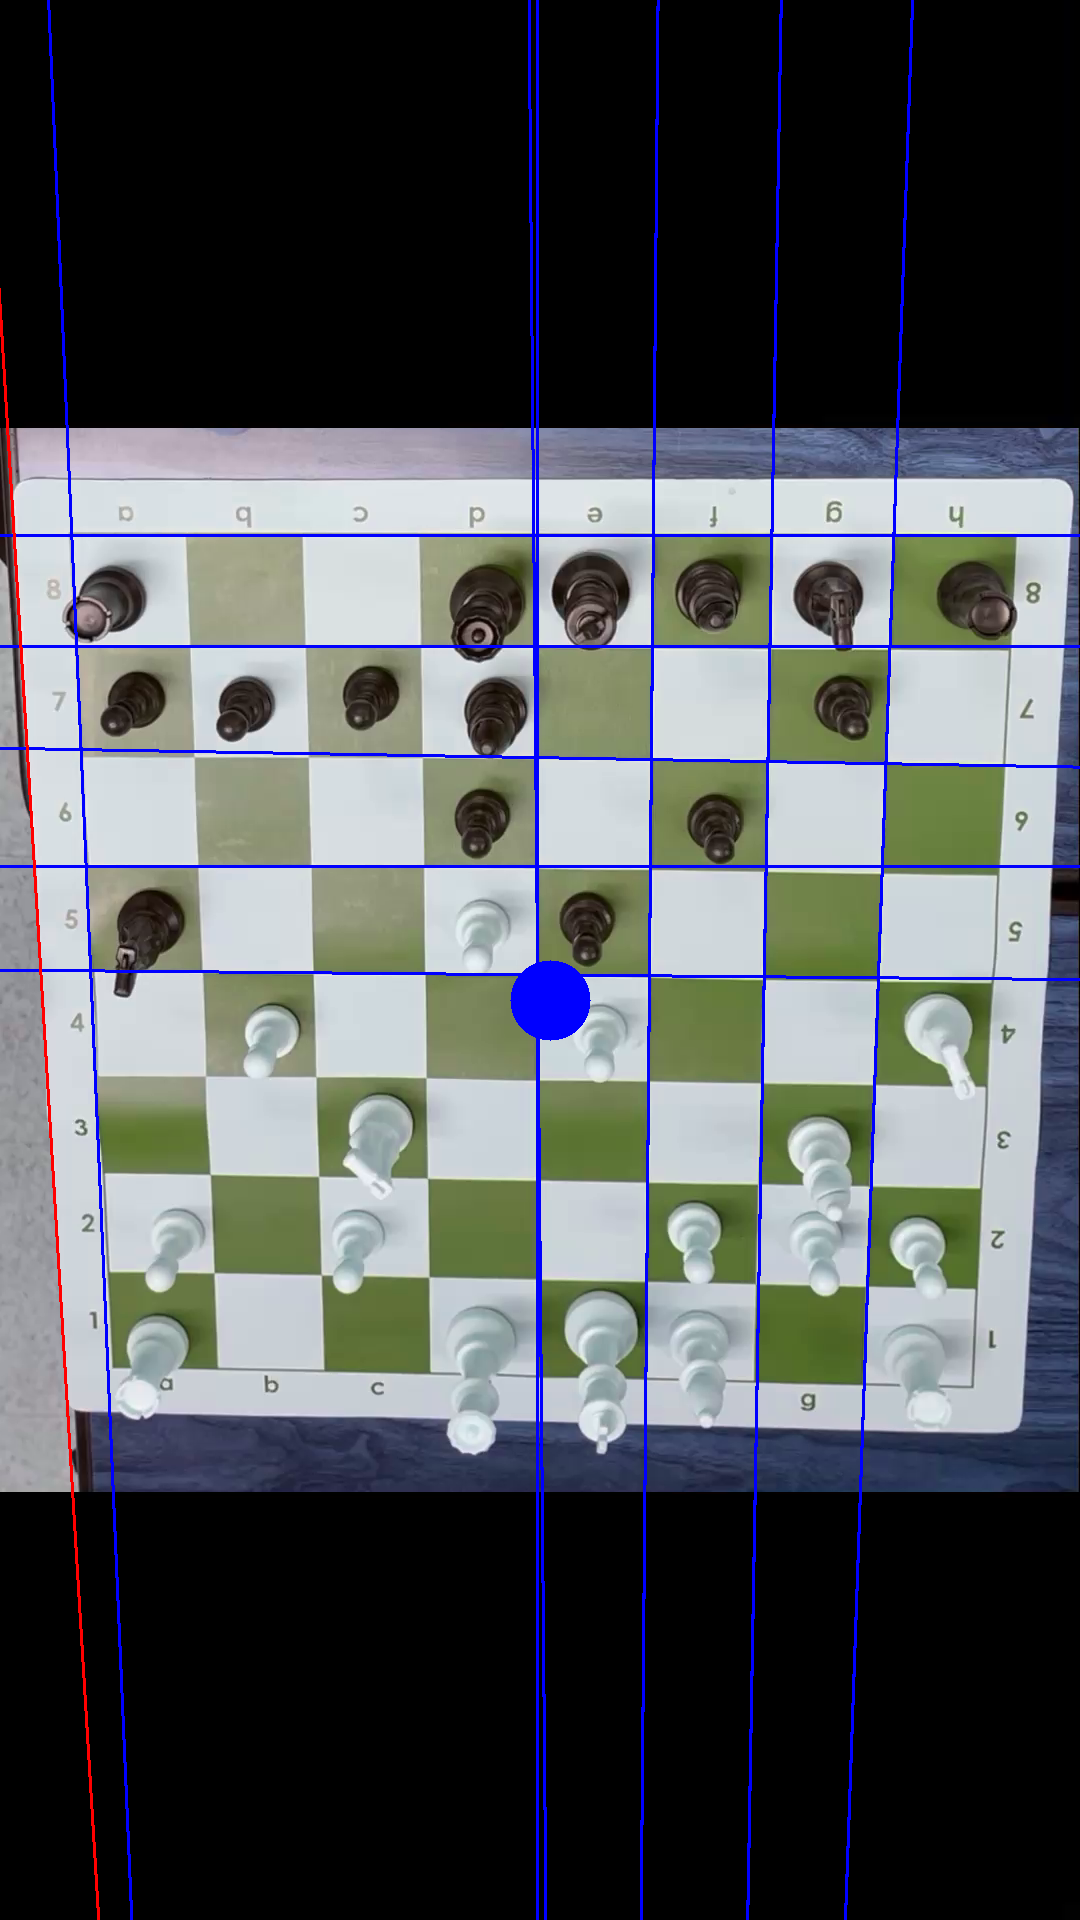

(0, 1)
isleftSmallThanRight  False
isTopSmallThanBottom  False
(920, 920, 3)
veritcalline  26
all vertical line is 
[(280.0, 0.061086524), (183.0, 0.061086524), (917.0, 0.07853982), (478.0, 0.06981317), (872.0, 0.07853982), (39.0, 0.05235988), (576.0, 0.06981317), (87.0, 0.061086524), (83.0, 0.05235988), (40.0, 0.061086524), (925.0, 0.07853982), (380.0, 0.06981317), (672.0, 0.06981317), (933.0, 0.10471976), (773.0, 0.07853982), (927.0, 0.09599311), (677.0, 0.07853982), (376.0, 0.061086524), (870.0, 0.07853982), (877.0, 0.08726646), (769.0, 0.06981317), (939.0, 0.06981317), (930.0, 0.09599311), (474.0, 0.061086524), (874.0, 0.08726646), (924.0, 0.06981317)]
------finding block
------------dis of line  -12.999116922042958
------------dis of curline 0
12.999116922042958
checking  75   178
<class 'float'> <class 'int'> <class 'int'>
--
------finding block
------------dis of line  -13.249045439298868
------------dis of curline 0
13.249045439298868
checking  75   178
<class 'float'> <class '

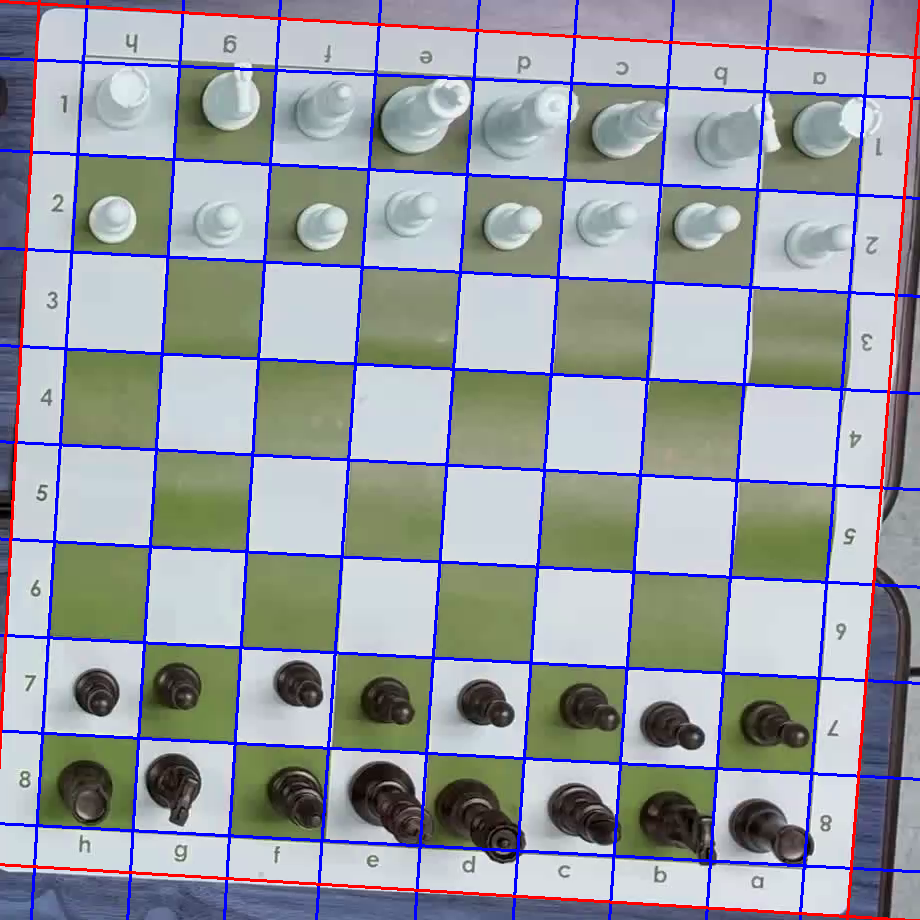

(7, 5)
isleftSmallThanRight  True
isTopSmallThanBottom  False


In [17]:
# load image

def testGrid(path):
    
    image = cv2.imread(path)
    print(image.shape)
    (VerticalResult, HorizontalResult), bounds\
    = gridDetect(image, 75, 178, (image.shape[0]//2, image.shape[1]//2), 200, 35, 75, 3)
    
    embededLine(image, VerticalResult + HorizontalResult, (0,0,255))

    bounds = [b for b in bounds if b != None]

    # gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # # Apply edge detection
    # edges = cv2.Canny(gray, 50, 150)
    # lines = cv2.HoughLines(edges, 1, np.pi / 360, 200)
    # myLine = [tuple(line[0]) for line in lines ]
    # allHorizontalLine = select_lineByDirection(myLine, True)

    #embededLine(image, allHorizontalLine, (0,255,0))
    embededLine(image, list(bounds), (255,0,0))
    point = (1000, 550)
    embededPoint(image, point)
    display(Image.fromarray(image))
    print(cellDetect(HorizontalResult, VerticalResult, point))
    print("isleftSmallThanRight ", isLeftSmallerThanRight(VerticalResult, True))
    print("isTopSmallThanBottom ", isLeftSmallerThanRight(HorizontalResult, False))

testGrid("examplePic/2_Move_rotate_student.png")
testGrid("examplePic/4_Move_studet.png")
testGrid("examplePic/6_Move_student.png")
testGrid("examplePic/8_Move_student.png")
testGrid("examplePic/2_Move_rotate_student_rotate.png")
testGrid("examplePic/4_Move_studet_rotated.png")
testGrid("examplePic/Bonus Long Video Label.png")

